# Experimento 13 — YOLO11n sobre os recortes com o macrófago preenchido pela cor do fundo

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** repetir o exp08 (YOLO11n sobre os recortes com o macrófago mascarado; mAP50 0,485 ± 0,109) mudando **um único fator**: **dataset**: recortes da etapa 05, em que a bbox do macrófago é preenchida com a cor mediana do fundo do recorte, e não com preto. As anotações são idênticas às do exp08.

**Hipótese:** O retângulo preto cria bordas artificiais fortes e uma área grande sem informação. Preencher com a cor do fundo deixa a imagem mais parecida com uma área vazia da lâmina.

**Por que partir do exp08:** os exp08, exp09 e exp10 mostraram que o tamanho e a geração do modelo não mudam o resultado (0,485 a 0,493). O YOLO11n treina cerca de 5× mais rápido que os modelos large, então as variações de pré-processamento são testadas com ele.

| | |
|---|---|
| **Dataset** | `02_datasets_derivados/05_recortes_512_macrofago_cor_fundo/` (gerado por `01_preprocessamento/05_mascarar_macrofago_cor_fundo.ipynb`) |
| **Folds YOLO** | `05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/` (montados por este notebook, com links simbólicos para o dataset) |
| **Runs** | `05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/runs/fold_1..fold_6/` |
| **Base** | exp08 (`03_experimentos anteriores/exp08_yolo11n_sem_macrofago/`) |

**Configuração:** `yolo11n.pt`, 150 épocas, patience 40, batch 16, AdamW, lr0 5e-4, lrf 0.01, cos_lr, single_cls, seed 42; aumento de dados hsv 0.03/0.9/0.6, degrees 15, flipud 0.5, mixup 0.1, mais os padrões do Ultralytics; imgsz 512.

**Validação:** os mesmos 6 folds por lâmina dos experimentos anteriores (5 lâminas de treino, 1 de validação e 2 de teste; ver `01_preprocessamento/divisao_folds_por_lamina.jpeg`), com métricas agregadas por fold e por lâmina.

## Resultado

**mAP50 0,488 ± 0,130** (exp08: 0,485 ± 0,109; Δ +0,003) · mAP50-95 0,187 ± 0,047 · P 0,506 · R 0,550

- mAP50 0,488 ± 0,130, +0,002 em relação ao exp08: sem efeito. Foi melhor em 3 dos 6 folds.
- Nenhuma lâmina mudou de forma consistente. A leish_1 caiu no fold 3 (0,423), e o desvio entre folds aumentou.
- O fold 4 chegou ao limite de 150 épocas (melhor época: 143), então poderia ter treinado mais.
- Conclusão: a cor usada para apagar o macrófago (preto ou cor do fundo) não importa. A máscara preta, mais simples, continua sendo a referência.

Detalhes por fold e por lâmina: `README.html` desta pasta.


## Utilização da GPU

In [1]:
!nvidia-smi

Wed Nov 18 09:34:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0  On |                  N/A |
| 36%   50C    P1             48W /  300W |    1298MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''


In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V


Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")


## Estrutura do Dataset

- 8 lâminas anotadas no formato YOLO; recortes 512×512 centrados em macrófagos infectados: recortes 512×512 com a bbox do macrófago preenchida pela cor mediana do fundo.
- Classes do `obj.names` (mantido igual ao original): `0 Non-macrophages`, `1 macrophage` (ausente: região apagada), `2 leishmania` (**alvo**: fora do macrófago), `3 inside-macrophage` (ausente).
- Só a classe `leishmania` é usada, remapeada para o índice `0` (detector de classe única).

![Divisão dos folds por lâmina](../01_preprocessamento/divisao_folds_por_lamina.jpeg)

## Parâmetros do experimento

In [7]:
# Diretório deste experimento (na raiz do projeto)
diretorio_experimento = os.path.join(diretorio_raiz, "05_novos_experimentos", "exp13_yolo11n_mascara_cor_fundo")

# Dataset: recortes 512×512 com a bbox do macrófago preenchida pela cor mediana do fundo
# (gerado por 01_preprocessamento/05_mascarar_macrofago_cor_fundo.ipynb)
diretorio_recortes = os.path.join(diretorio_raiz, "02_datasets_derivados", "05_recortes_512_macrofago_cor_fundo")

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Estrutura YOLO por fold e runs ficam dentro da pasta do experimento
diretorio_yolo_folds = os.path.join(diretorio_experimento, "folds_yolo")
diretorio_runs = os.path.join(diretorio_experimento, "runs")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-nano (cópia local; baixados pela Ultralytics se faltarem)
caminho_pesos_pretreinados = os.path.join(diretorio_experimento, 'yolo11n.pt')
if not os.path.isfile(caminho_pesos_pretreinados):
    caminho_pesos_pretreinados = 'yolo11n.pt'

tamanho_batch = 16

# Hiperparâmetros de treinamento: idênticos ao exp08
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados: jitter de cor (imagens em RGB), rotação, flip vertical (sem orientação
    # canônica em microscopia) e mixup; mosaico, flip horizontal, translação e escala seguem o padrão.
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')


,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")


Fold 1: treino=1064 | validação=126 | teste=378
Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")


6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds (YOLO11-nano, batch=16)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo11n.pt`. Se o `best.pt` de um fold já existir **e** o arquivo `fold_N/concluido.txt` indicar que o treino terminou, o fold é pulado.

In [11]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    marcador = os.path.join(diretorio_runs, nome_run, 'concluido.txt')
    if os.path.isfile(caminho_best) and os.path.isfile(marcador):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        with open(marcador, 'w') as f:
            f.write('treino concluído\n')
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.9, hsv_v=0.6, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (12,738 outputs left out)

                   all         96        831      0.647      0.537      0.579      0.277


Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/runs/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/runs/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [12]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4021.6±722.5 MB/s, size: 219.4 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 6.1Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.7it/s 0.1s<8.6s

... (69 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 42.3it/s 0.7s

                   all        480       1634      0.358      0.485      0.359      0.141


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.549250,0.565998,0.528403,0.176187
2,"leish_2, leish_7",0.608969,0.648547,0.621358,0.244795
3,"leish_1, leish_8",0.390434,0.381788,0.314138,0.129759
4,"leish_4, leish_9",0.471227,0.606639,0.479977,0.198695
5,"leish_1, leish_7",0.660527,0.611753,0.621942,0.229341
6,"leish_2, leish_8",0.358100,0.485496,0.358957,0.140746


In [13]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)


,média,desvio_padrão
precisao,0.5064,0.1207
recall,0.5500,0.0994
mAP50,0.4875,0.1298
mAP50-95,0.1866,0.0465


## Comparação com os experimentos anteriores

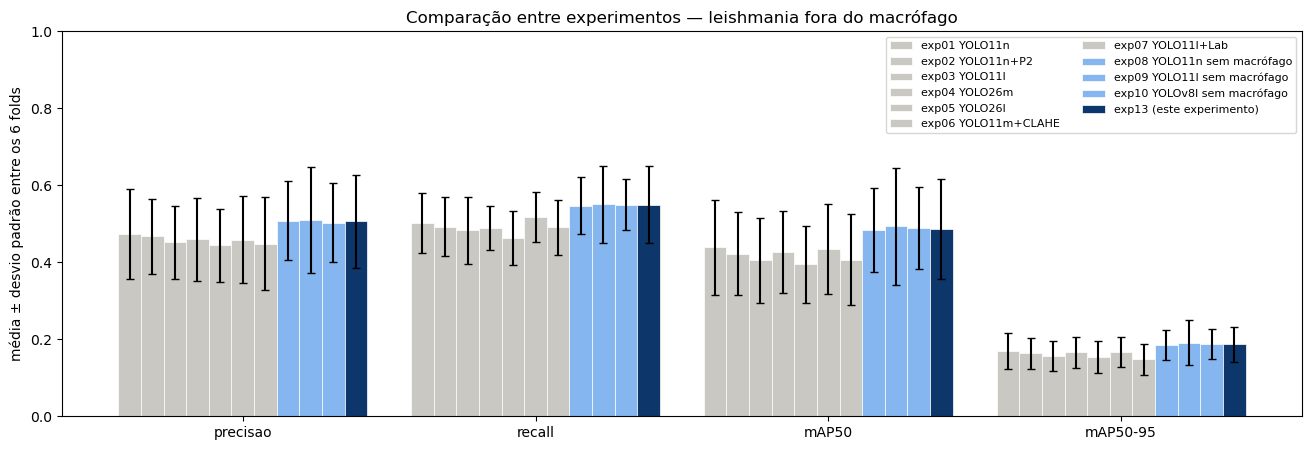

In [14]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores (numeração do resumo_experimentos.html).
# exp01-07: recortes com o macrófago visível; exp08-10: recortes com o macrófago mascarado.
# A base direta deste experimento é o exp08 (YOLO11n): só um fator muda.
anteriores = {
    'exp01 YOLO11n':               ((0.4735, 0.1164), (0.5012, 0.0780), (0.4391, 0.1229), (0.1695, 0.0457)),
    'exp02 YOLO11n+P2':            ((0.4672, 0.0981), (0.4922, 0.0763), (0.4226, 0.1083), (0.1640, 0.0405)),
    'exp03 YOLO11l':               ((0.4520, 0.0945), (0.4832, 0.0864), (0.4048, 0.1095), (0.1576, 0.0391)),
    'exp04 YOLO26m':               ((0.4595, 0.1079), (0.4894, 0.0567), (0.4272, 0.1068), (0.1659, 0.0396)),
    'exp05 YOLO26l':               ((0.4442, 0.0946), (0.4632, 0.0705), (0.3943, 0.1000), (0.1538, 0.0417)),
    'exp06 YOLO11m+CLAHE':         ((0.4581, 0.1132), (0.5170, 0.0652), (0.4345, 0.1175), (0.1670, 0.0391)),
    'exp07 YOLO11l+Lab':           ((0.4485, 0.1206), (0.4904, 0.0707), (0.4067, 0.1180), (0.1483, 0.0407)),
    'exp08 YOLO11n sem macrófago': ((0.5077, 0.1022), (0.5471, 0.0743), (0.4850, 0.1090), (0.1841, 0.0391)),
    'exp09 YOLO11l sem macrófago': ((0.5098, 0.1364), (0.5508, 0.1003), (0.4930, 0.1516), (0.1915, 0.0588)),
    'exp10 YOLOv8l sem macrófago': ((0.5029, 0.1033), (0.5491, 0.0664), (0.4889, 0.1065), (0.1876, 0.0381)),
}
metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']

nomes_exp = list(anteriores) + ['exp13 (este experimento)']
medias_exp = [[m for m, _ in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'média'])]
desvios_exp = [[d for _, d in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'desvio_padrão'])]

# cinza = macrófago visível; azul claro = mascarado (exp08-10); azul escuro = este experimento
cores = ['#c9c8c2'] * 7 + ['#86b6ef'] * (len(anteriores) - 7) + ['#0d366b']

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.85 / n_exp
fig, ax = plt.subplots(figsize=(16, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=3, label=nome, color=cores[i], edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('média ± desvio padrão entre os 6 folds')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [15]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5045.6±449.2 MB/s, size: 220.1 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 6.0Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp13_yolo11n_mascara_cor_fundo/folds_yolo/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 20.0it/s 0.1s

... (119 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 44.2it/s 0.5s

                   all        353        992      0.374      0.452      0.348      0.141


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.645540,0.297232,0.422942,0.191470
1,leish_1,5,0.669250,0.504212,0.557889,0.225842
2,leish_2,2,0.398210,0.496885,0.364962,0.144334
3,leish_2,6,0.374961,0.549844,0.392117,0.145819
4,leish_3,1,0.380136,0.249142,0.276868,0.122584
5,leish_4,4,0.344112,0.226561,0.200551,0.093694
6,leish_5,1,0.554508,0.567196,0.532529,0.177528
7,leish_7,2,0.672162,0.702146,0.702134,0.276789
8,leish_7,5,0.673728,0.655278,0.660718,0.239529
9,leish_8,3,0.404363,0.406250,0.351585,0.139494


In [16]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)


precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6574  0.0168     2  0.4007  0.1464     2  0.4904  0.0954     2   
leish_2   0.3866  0.0164     2  0.5234  0.0374     2  0.3785  0.0192     2   
leish_3   0.3801     NaN     1  0.2491     NaN     1  0.2769     NaN     1   
leish_4   0.3441     NaN     1  0.2266     NaN     1  0.2006     NaN     1   
leish_5   0.5545     NaN     1  0.5672     NaN     1  0.5325     NaN     1   
leish_7   0.6729  0.0011     2  0.6787  0.0331     2  0.6814  0.0293     2   
leish_8   0.3892  0.0214     2  0.4289  0.0321     2  0.3500  0.0022     2   
leish_9   0.5228     NaN     1  0.6589     NaN     1  0.5592     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.2087  0.0243     2  
leish_2   0.1451  0.0011     2  
leish_3   0.1226     NaN     1  
leish_4   0.0937     NaN     1  
leish_5   0.1775     NaN     1  
leish_7   0.2582  0.0263     2  
leish_8   0.1403  0.0012     2  
leish_9   0.2294     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. Imagens em RGB (região do macrófago preenchida com a cor do fundo).

In [17]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_bgr = cv2.imread(caminho_imagem)
    altura, largura = img_bgr.shape[:2]
    eixo.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']


Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


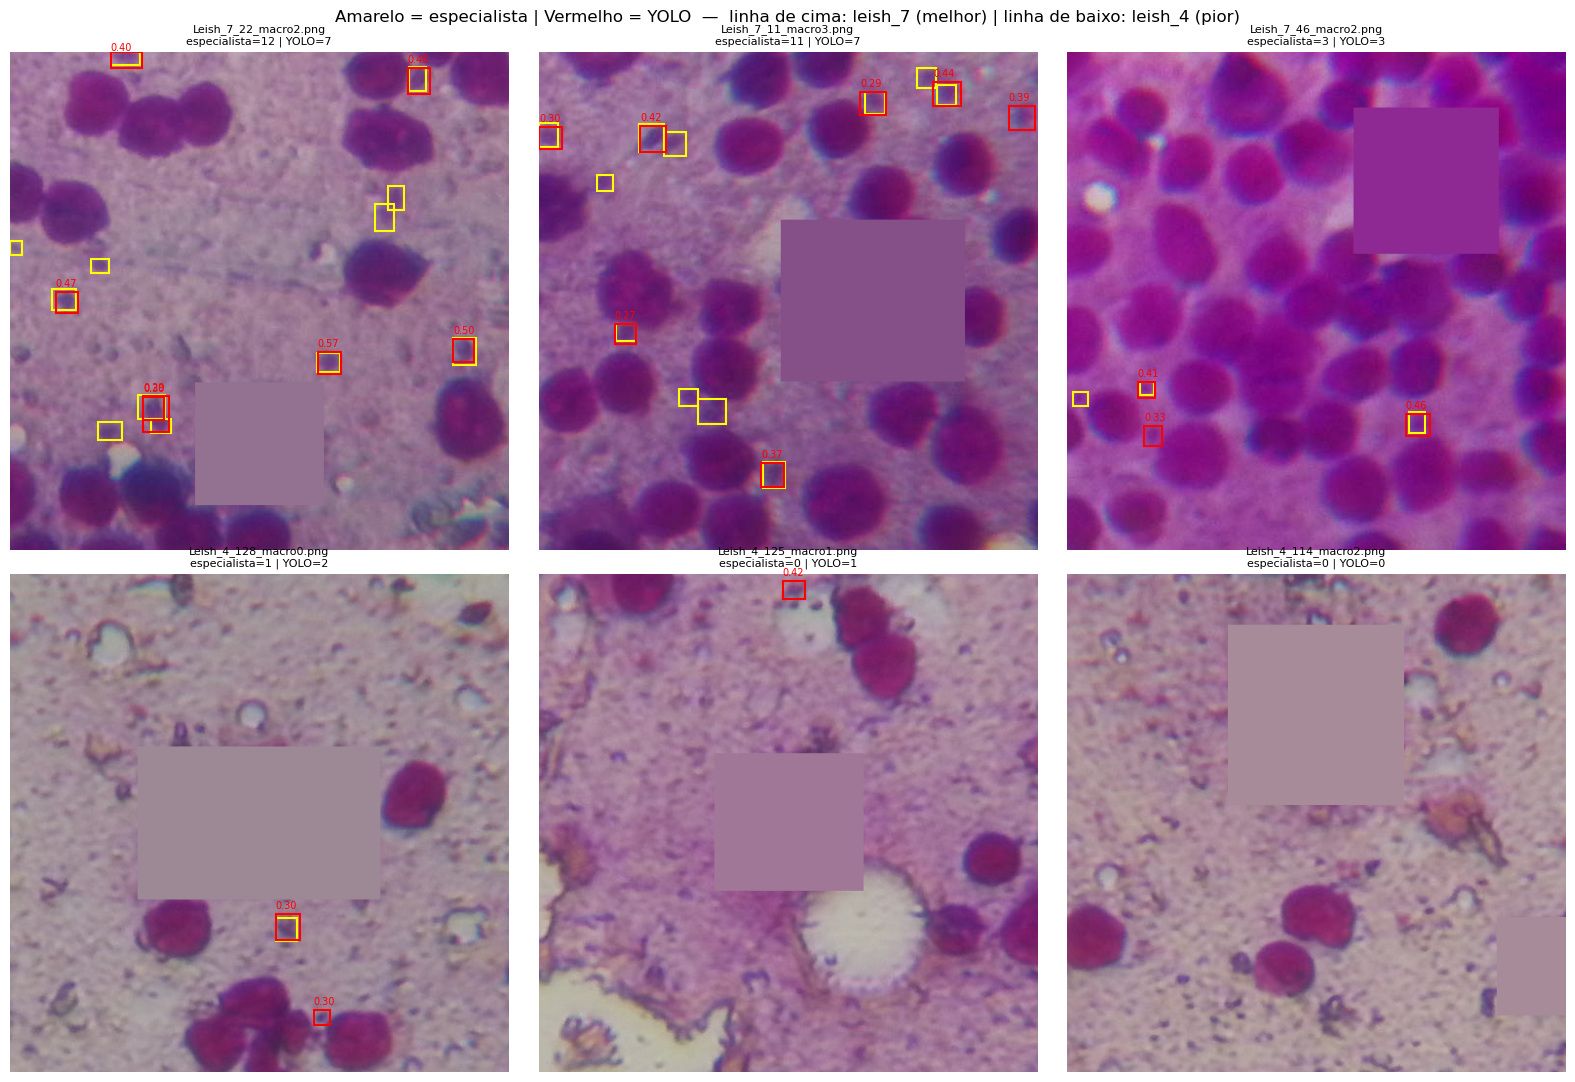

In [18]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()
